In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import squidpy as sq
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

In [2]:
in_dir = "../../results/04_spatial_clustering/01_run_cellcharter"
out_dir = '../../results/04_spatial_clustering/04_compare_niche'

os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f"{in_dir}/adata_cellcharter_merged.h5ad")

df = adata.obs[['cluster_cellcharter', 'sample']].copy()

In [4]:
df

,cluster_cellcharter,sample
AACCAAGGTATCAGGC-1_0,3,sample_15837
AACCGCCAGACTACTT-1_0,1,sample_15837
AACGAATTGACCGGTT-1_0,8,sample_15837
AACTCAACCTTGACCA-1_0,1,sample_15837
AACTGCCTCGATAGGT-1_0,1,sample_15837
...,...,...
TGTTCTGCTCTGTCGT-1_11,12,sample_X1912
TGTTGGAACCTTCCGC-1_11,10,sample_X1912
TGTTGGAACGAGGTCA-1_11,10,sample_X1912
TGTTGGATGGACTTCT-1_11,11,sample_X1912


In [5]:
# add group info to adata.obs based on sample column in adata.obs
group_dict = {
    'sample_15837': 'SRC',
    'sample_15852': 'SRC',
    'sample_16512': 'SRC',
    'sample_21022': 'SRC',
    'sample_8262': 'SRC',
    'sample_B23-03794-5': 'Normal',
    'sample_B23-05785-7-1': 'Normal',
    'sample_B23-05785-7-2': 'Normal',
    'sample_X1842': 'LN',
    'sample_X1845': 'LN',
    'sample_X1899': 'LN',
    'sample_X1912': 'LN'
}


In [6]:
df

,cluster_cellcharter,sample
AACCAAGGTATCAGGC-1_0,3,sample_15837
AACCGCCAGACTACTT-1_0,1,sample_15837
AACGAATTGACCGGTT-1_0,8,sample_15837
AACTCAACCTTGACCA-1_0,1,sample_15837
AACTGCCTCGATAGGT-1_0,1,sample_15837
...,...,...
TGTTCTGCTCTGTCGT-1_11,12,sample_X1912
TGTTGGAACCTTCCGC-1_11,10,sample_X1912
TGTTGGAACGAGGTCA-1_11,10,sample_X1912
TGTTGGATGGACTTCT-1_11,11,sample_X1912


In [7]:
# compute proportion of each cluster in each sample
proportion_df = df.groupby(['sample', 'cluster_cellcharter']).size().unstack(fill_value=0)
proportion_df = proportion_df.div(proportion_df.sum(axis=1), axis=0)

#proportion_df = proportion_df.transpose()
proportion_df.columns.name = ''
proportion_df.reset_index(inplace=True)
proportion_df['group'] = proportion_df['sample'].map(group_dict)

In [8]:
proportion_df

,sample,0,1,2,3,4,5,6,7,8,9,10,11,12,group
0,sample_8262,0.000000,0.768262,0.000000,0.229219,0.000000,0.000000,0.000000,0.000000,0.000000,0.002519,0.000000,0.000000,0.000000,SRC
1,sample_15837,0.011940,0.498507,0.029851,0.385075,0.000000,0.014925,0.000000,0.000000,0.044776,0.011940,0.000000,0.002985,0.000000,SRC
2,sample_15852,0.000000,0.544000,0.174000,0.232000,0.000000,0.000000,0.000000,0.000000,0.000000,0.050000,0.000000,0.000000,0.000000,SRC
3,sample_16512,0.000000,0.533217,0.227273,0.087413,0.003497,0.003497,0.001748,0.000000,0.010490,0.054196,0.000000,0.078671,0.000000,SRC
4,sample_21022,0.010889,0.179673,0.174229,0.059891,0.000000,0.000000,0.441016,0.038113,0.012704,0.065336,0.000000,0.018149,0.000000,SRC
5,sample_B23-03794-5,0.000000,0.018245,0.086978,0.055736,0.000000,0.551112,0.000000,0.000000,0.086978,0.050487,0.000000,0.150462,0.000000,Normal
6,sample_B23-05785-7-1,0.290821,0.003013,0.045391,0.014260,0.190400,0.000201,0.046596,0.140590,0.143603,0.011850,0.003013,0.108857,0.001406,Normal
7,sample_B23-05785-7-2,0.113026,0.005411,0.077756,0.003808,0.202806,0.001804,0.078758,0.328657,0.065130,0.011623,0.000401,0.110020,0.000802,Normal
8,sample_X1842,0.000000,0.009424,0.008377,0.004188,0.106806,0.000000,0.117277,0.000000,0.003141,0.070157,0.321466,0.012565,0.346597,LN
9,sample_X1845,0.016194,0.006073,0.018219,0.028340,0.014170,0.000000,0.034413,0.000000,0.012146,0.046559,0.352227,0.062753,0.408907,LN


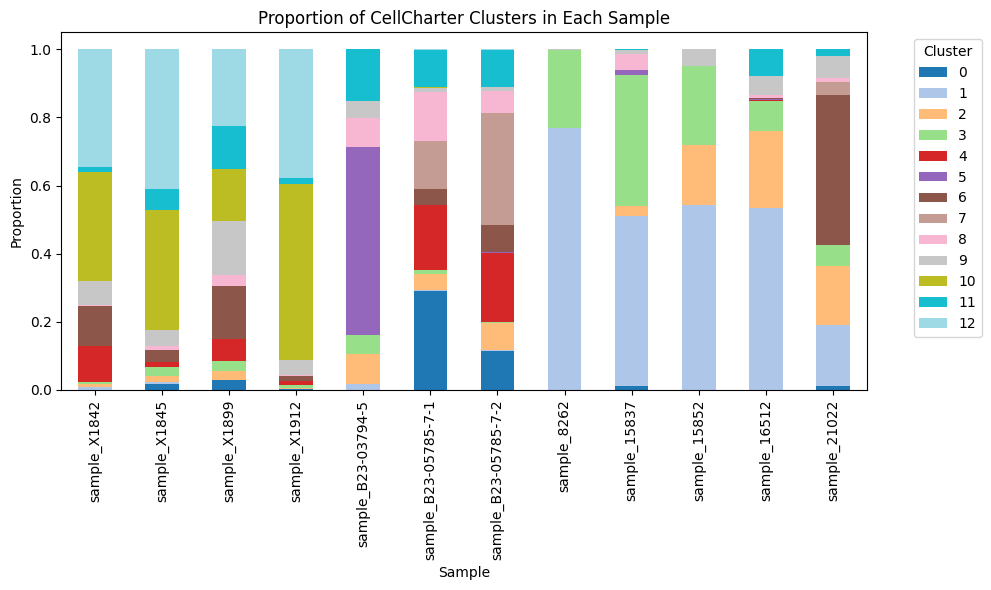

In [9]:
# plot stacked barplot of proportion_df
proportion_df.set_index('sample', inplace=True)
proportion_df = proportion_df.sort_values(by='group')

proportion_df.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.ylabel('Proportion')
plt.xlabel('Sample')
plt.title('Proportion of CellCharter Clusters in Each Sample')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

1_Normal vs. 1_SRC: Mann-Whitney-Wilcoxon test two-sided, P_val:3.571e-02 U_stat=0.000e+00
2_Normal vs. 2_SRC: Mann-Whitney-Wilcoxon test two-sided, P_val:7.857e-01 U_stat=6.000e+00
3_Normal vs. 3_SRC: Mann-Whitney-Wilcoxon test two-sided, P_val:3.571e-02 U_stat=0.000e+00
4_Normal vs. 4_SRC: Mann-Whitney-Wilcoxon test two-sided, P_val:1.719e-01 U_stat=1.200e+01
0_Normal vs. 0_SRC: Mann-Whitney-Wilcoxon test two-sided, P_val:2.662e-01 U_stat=1.150e+01


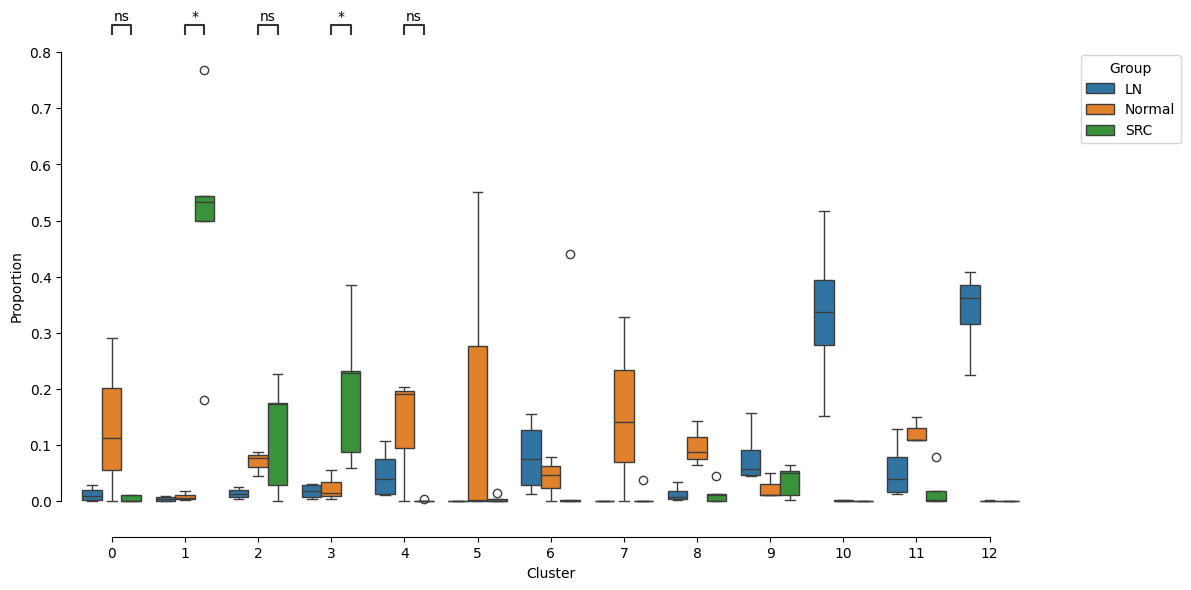

In [10]:
# plot boxplot of proportion of each cluster by group
melted_df = proportion_df.reset_index().melt(id_vars=['sample', 'group'], var_name='cluster_cellcharter', value_name='proportion')

# plot boxplot
plt.figure(figsize=(12, 6))
ax = sns.boxplot(data=melted_df, x='cluster_cellcharter', y='proportion', hue='group')
sns.despine(offset=10, trim=True, ax=ax)

pairs=[(('0', "SRC"), ('0', "Normal")),
       (('1', "SRC"), ('1', "Normal")),
       (('2', "SRC"), ('2', "Normal")),
       (('3', "SRC"), ('3', "Normal")),
       (('4', "SRC"), ('4', "Normal")),]

annotator = Annotator(ax, pairs, data=melted_df, x='cluster_cellcharter', y='proportion', hue='group')
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside')
annotator.apply_and_annotate()

plt.ylabel('Proportion')
plt.xlabel('Cluster')
plt.title('')
plt.legend(title='Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

In [11]:
melted_df

,sample,group,cluster_cellcharter,proportion
0,sample_X1842,LN,0,0.000000
1,sample_X1845,LN,0,0.016194
2,sample_X1899,LN,0,0.029152
3,sample_X1912,LN,0,0.002398
4,sample_B23-03794-5,Normal,0,0.000000
...,...,...,...,...
151,sample_8262,SRC,12,0.000000
152,sample_15837,SRC,12,0.000000
153,sample_15852,SRC,12,0.000000
154,sample_16512,SRC,12,0.000000


In [12]:
melted_df.to_csv(f"{out_dir}/cellcharter_cluster_proportions_per_sample.tsv", sep="\t", index=False)